# EDA 2 · Review types

1. **Most common types** and how positive they are.
2. **Types over time**, per game with patch days.
3. **Types after patches**: which grow in the week after hotfixes, updates and major patches.

Topics with the same label (one theme in several languages) count together as one **type**. Only kept reviews have a topic; shares are among reviews with a type (not too short, not without a clear topic).

In [1]:
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

from src.config import TOPIC_NOISE, TOPIC_SHORT, game_names
from src.db import read
from src.features.daily import collection, daily_series, daily_topics, label_counts, patch_days, weekly
from src.features.events import SIZES, study_patches
from src.text.topics import topic_names
from src.viz.charts import per_game_panels, use_style

use_style()

In [2]:
TOPIC_GAMES = 10            # games in the "over time" charts (most reviews)
BASELINE = (-14, -1)        # patches: days compared with
POST = (0, 6)               # ... and the patch day and the 6 days after

In [3]:
names = game_names()
collected = collection()
games = collected.index[collected["complete"].ne(False)]
labels = topic_names(read.topics(), with_id=False)
SHORT, NOISE = labels[TOPIC_SHORT], labels[TOPIC_NOISE]
by_topic = read.topics_by_language(games)
by_topic["type"] = by_topic["topic_id"].map(labels)
totals = by_topic.groupby("type")["n"].sum()
print(f"{totals.sum():,} kept reviews with a topic: {totals[SHORT] / totals.sum():.0%} too short, "
      f"{totals[NOISE] / totals.sum():.0%} no clear type")

typed = by_topic[~by_topic["type"].isin([SHORT, NOISE])]
counts = typed.assign(positive=typed["n"].where(typed["voted_up"].astype(bool), 0)).groupby("type")[["n", "positive"]].sum()
stats = pd.DataFrame({"reviews": counts["n"], "positive": counts["positive"] / counts["n"],
                      "share": counts["n"] / counts["n"].sum()})
print(f"{stats['reviews'].sum():,} reviews in {len(stats)} types")

25,025,935 kept reviews with a topic: 36% too short, 13% no clear type
12,741,190 reviews in 45 types


## 1. Most common types

Bar color: share of positive reviews (red = mostly 👎).

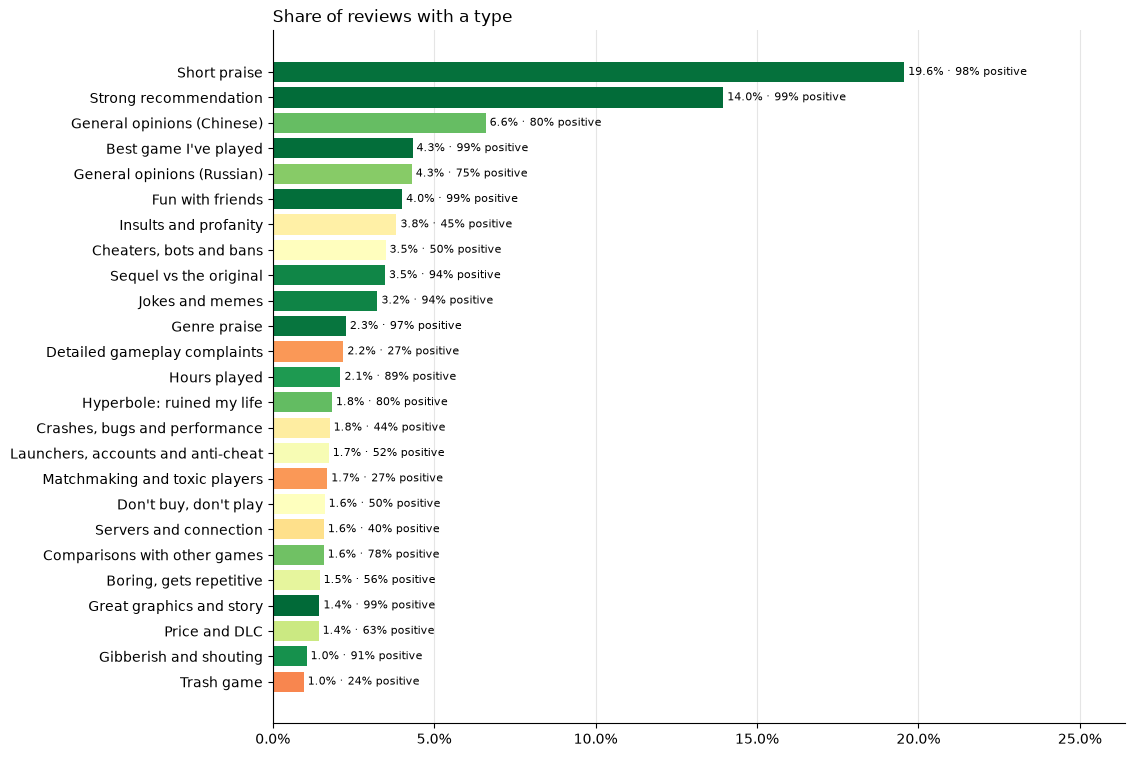

In [4]:
top = stats.nlargest(25, "reviews").iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 9))
ax.barh(top.index.map(lambda s: textwrap.shorten(s, 55)), top["share"], color=plt.cm.RdYlGn(top["positive"]))
for y, (share, positive) in enumerate(zip(top["share"], top["positive"], strict=True)):
    ax.text(share, y, f" {share:.1%} · {positive:.0%} positive", va="center", fontsize=8)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(0, top["share"].max() * 1.35)
ax.grid(axis="y", visible=False)
ax.set_title("Share of reviews with a type", loc="left");

**Most negative and most positive types** (at least 0.5% of reviews).

In [5]:
common = stats[stats["share"] >= 0.005].sort_values("positive")
shown = common if len(common) <= 20 else pd.concat([common.head(12), common.tail(8)])
shown.style.format({"reviews": "{:,}", "positive": "{:.0%}", "share": "{:.1%}"}).background_gradient(
    subset="positive", cmap="RdYlGn", vmin=0, vmax=1)

,reviews,positive,share
type,,,
Trash game,"122,297",24%,1.0%
Updates made it worse,"68,207",27%,0.5%
Detailed gameplay complaints,"278,968",27%,2.2%
Matchmaking and toxic players,"215,258",27%,1.7%
Won't launch or log in,"116,972",37%,0.9%
Servers and connection,"201,939",40%,1.6%
"Game modes: campaign, PvE, extraction","67,075",43%,0.5%
"Crashes, bugs and performance","224,658",44%,1.8%
Insults and profanity,"488,364",45%,3.8%


## 2. Types over time

Weekly share of each game's 4 biggest types for the `TOPIC_GAMES` games with the most reviews (weeks with at least 30 reviews with a type), with patch days.

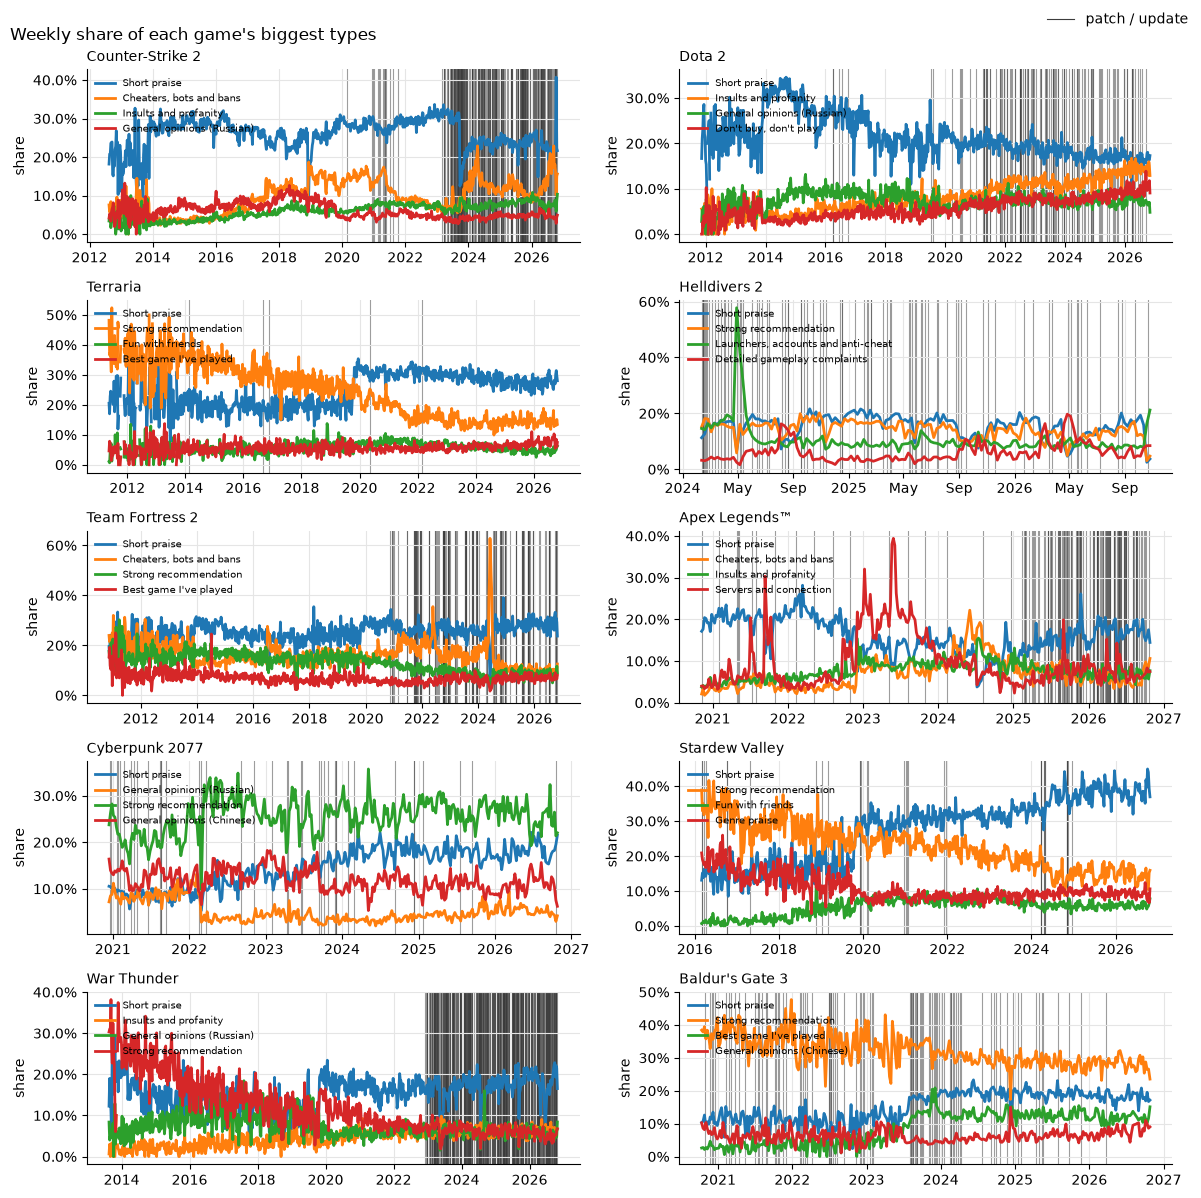

In [6]:
series = daily_series(games)
by_label = label_counts(daily_topics(games)).drop(columns=[SHORT, NOISE], errors="ignore")
biggest = series.groupby(level="appid")["n"].sum().nlargest(TOPIC_GAMES).index
week_counts = weekly(by_label[by_label.index.get_level_values("appid").isin(biggest)])
week_totals = week_counts.sum(axis=1)
shares = week_counts.div(week_totals.where(week_totals >= 30), axis=0)
top_types = week_counts.groupby(level="appid").sum().apply(lambda row: row.nlargest(4).index.tolist(), axis=1)
shown = pd.concat({appid: shares.loc[appid, top_types[appid]] for appid in biggest}, names=["appid", "day"])
per_game_panels(shown, "Weekly share of each game's biggest types", "share", patches=patch_days(biggest), percent=True)

## 3. Types after patches

For each patch that is isolated (no other patch in the 14 days before), outside the game's launch and with enough reviews before it: every type's share of the game's reviews in the week after vs the 2 weeks before (percentage points), averaged over patches of a size. The 20 types with the clearest change; · marks a mean change that is not clear (|t| < 3).

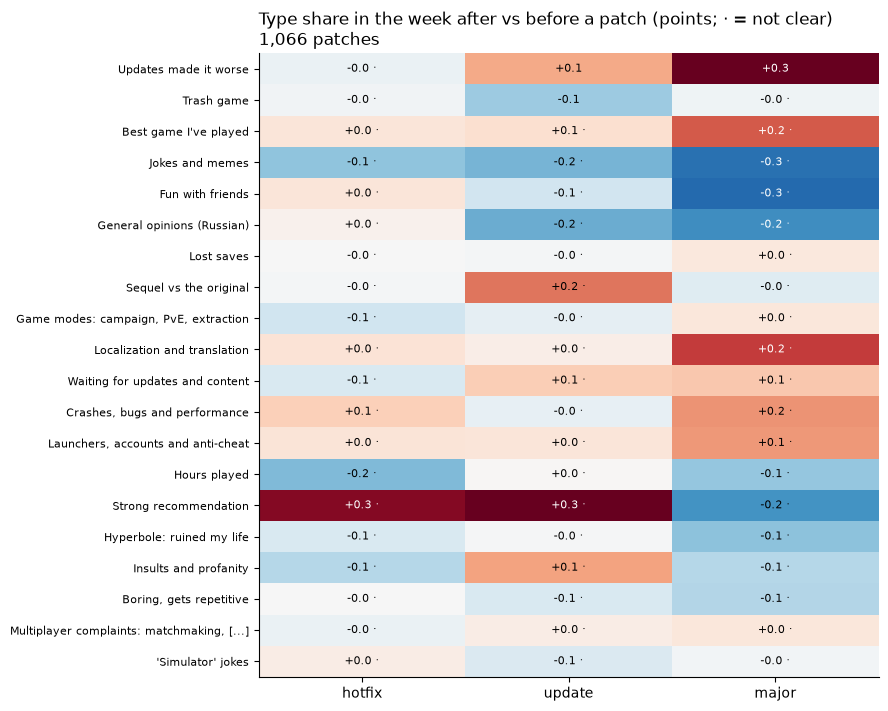

In [7]:
events = study_patches(series)


def window_sum(values, event, start, end):
    return values.loc[event.appid].loc[event.day + pd.Timedelta(days=start) : event.day + pd.Timedelta(days=end)].sum()


rows = []
for e in events.itertuples():
    base, post = window_sum(by_label, e, *BASELINE), window_sum(by_label, e, *POST)
    if base.sum() >= 30 and post.sum() >= 10:
        rows.append((post / post.sum() - base / base.sum()).rename(e.Index))
topic_change = pd.DataFrame(rows).join(events["size"])
stats_by_size = topic_change.groupby("size").agg(["mean", "std", "count"])
mean = stats_by_size.xs("mean", axis=1, level=1).T
t = mean / (stats_by_size.xs("std", axis=1, level=1).T / np.sqrt(stats_by_size.xs("count", axis=1, level=1).T))
shown = mean.loc[t.abs().max(axis=1).sort_values(ascending=False).index[:20]]
shown = shown.reindex(columns=[s for s in SIZES if s in shown.columns])

fig, ax = plt.subplots(figsize=(8, 0.33 * len(shown) + 1.5))
limit = np.nanmax(np.abs(shown.to_numpy()))
ax.imshow(shown, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
for (i, j), v in np.ndenumerate(shown.to_numpy()):
    marker = "" if abs(t.loc[shown.index[i], shown.columns[j]]) >= 3 else " ·"
    ax.text(j, i, f"{v * 100:+.1f}{marker}", ha="center", va="center", fontsize=8,
            color="white" if abs(v) > 0.6 * limit else "black")
ax.set_xticks(range(len(shown.columns)), shown.columns)
ax.set_yticks(range(len(shown)), [textwrap.shorten(s, 45) for s in shown.index], fontsize=8)
ax.grid(False)
ax.set_title(f"Type share in the week after vs before a patch (points; · = not clear)\n{len(topic_change):,} patches",
             loc="left");